# 02 - Retrospective replay on real public screens

This is the evidence. Everything else in Loopwise is machinery; this notebook
asks whether the machinery pays for itself on data somebody actually measured.

**The method.** Take a public dataset where every compound has been measured.
Hide all the labels. A policy selects a batch; we reveal only that batch's
labels; the model retrains; repeat. Because the full answer key exists, we can
compute what no live campaign can: what each policy *would have* found, on the
same data, with the same model and budget.

**Two datasets, chosen because they disagree:**

| Dataset | What it is | Hit rate | Why it is here |
| --- | --- | --- | --- |
| **Tox21 NR-AR** | 7,258 compounds screened against the androgen receptor | 4.2% | A realistically scarce primary screen |
| **BACE-1** | 1,513 beta-secretase inhibitors with measured IC50 | 44.6% at pIC50 >= 7 | A dose-response set, where potency is continuous |

**Spoiler, stated up front:** on one of these datasets greedy wins on hits, and
on the other greedy wins on hits *and* produces the worst model of any policy.
Neither result is the tidy one. Both are reported.

In [1]:
import sys
from pathlib import Path

# Figures and tables land in results/ so the committed notebooks and the README
# reference the same files.
ROOT = Path.cwd()
if not (ROOT / "loopwise").exists():
    ROOT = ROOT.parent
FIGDIR = ROOT / "results" / "figures"
TABDIR = ROOT / "results" / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)
print("loopwise", __import__("loopwise").__version__, "| figures ->", FIGDIR)

loopwise 0.1.0 | figures -> /home/user/loopwise/results/figures


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from loopwise.datasets import load_bace, load_tox21
from loopwise.replay import compare_policies, plot_comparison

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

POLICIES = ["random", "greedy", "uncertainty", "bald", "thompson", "hybrid", "kdpp"]
SEEDS = (0, 1, 2, 3, 4)
def forest():
    return RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=2)

## Dataset 1: Tox21 NR-AR

The Tox21 Data Challenge (2014) screened ~7,800 compounds against 12
nuclear-receptor and stress-response assays. We use the androgen receptor
(NR-AR) assay as a binary screen: 4.2% of the 7,258 measured compounds are
active. That scarcity is the point -- it is the regime where a greedy policy
can look excellent while learning nothing.

Compounds arrive as SMILES strings (text, e.g. `CC(=O)Oc1ccccc1C(=O)O` for
aspirin), which a model cannot consume. We convert them to **Morgan
fingerprints**: for every atom, describe the neighbourhood within 2 bonds, hash
each description into one of 512 buckets, set that bit. Molecules sharing
substructures share bits. This is the standard representation for ligand-based
screening (Rogers & Hahn, 2010).

In [3]:
tox21, tox21_info = load_tox21("NR-AR", n_bits=512, radius=2)
print({k: v for k, v in tox21_info.items() if k != "feature_cols"})
tox21[["mol_id", "smiles", "label"]].head()

{'featurizer': 'morgan_ecfp4', 'n_bits': 512, 'radius': 2, 'n_unparseable': 7, 'dataset': 'Tox21', 'target': 'NR-AR', 'source_url': 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz', 'citation': 'Tox21 Data Challenge 2014; distributed via MoleculeNet (Wu et al., Chem. Sci. 2018). Public domain (US government).', 'n_compounds': 7258, 'n_actives': 308, 'hit_rate': 0.0424, 'task': 'classification'}


,mol_id,smiles,label
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0
2,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0
3,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0
4,TOX5110,CC(C)(C)OOC(C)(C)CCC(C)(C)OOC(C)(C)C,0


### A note on how model quality is measured

PR-AUC (area under the precision-recall curve) rather than ROC-AUC: with a 4%
hit rate, a model can have a fine ROC-AUC while its top 96 predictions are
nearly all inactive, because ROC-AUC averages over thresholds nobody will act
on.

And it is computed on a **fixed 20% holdout that no policy can select.** This
is not fussiness. If you score the model on whatever is left unselected, a
successful policy is punished for its own success: greedy harvests the easy
actives, so the leftovers are the hard ones. We measured it -- scored that way,
greedy gets PR-AUC 0.037 and random gets 0.485, while greedy finds eight times
as many actives. That number describes the difficulty of the leftovers, not the
quality of the model. A fixed holdout keeps the measuring stick still.

In [4]:
tox21_frame, tox21_results = compare_policies(
    tox21,
    label_col="label",
    model_factory=forest,
    policies=POLICIES,
    seeds=SEEDS,
    feature_cols=tox21_info["feature_cols"],
    id_col="mol_id",
    budget=96,
    n_rounds=8,
    n_initial_labels=96,
    holdout_fraction=0.2,
    verbose=True,
)
TABDIR.mkdir(parents=True, exist_ok=True)
tox21_frame.to_csv(TABDIR / "02_tox21_nr_ar_rounds.csv", index=False)

[replay] policy=random seed=0


   random: 38/248 actives (15.3%) after 8 rounds of 96; final PR-AUC 0.474; rounds to 50% of actives: not reached; 5.6s
[replay] policy=random seed=1


   random: 44/261 actives (16.9%) after 8 rounds of 96; final PR-AUC 0.549; rounds to 50% of actives: not reached; 5.5s
[replay] policy=random seed=2


   random: 37/240 actives (15.4%) after 8 rounds of 96; final PR-AUC 0.460; rounds to 50% of actives: not reached; 5.4s
[replay] policy=random seed=3


   random: 24/241 actives (10.0%) after 8 rounds of 96; final PR-AUC 0.450; rounds to 50% of actives: not reached; 5.2s
[replay] policy=random seed=4


...

   kdpp: 71/248 actives (28.6%) after 8 rounds of 96; final PR-AUC 0.537; rounds to 50% of actives: not reached; 6.6s
[replay] policy=kdpp seed=1


   kdpp: 79/261 actives (30.3%) after 8 rounds of 96; final PR-AUC 0.552; rounds to 50% of actives: not reached; 6.2s
[replay] policy=kdpp seed=2


   kdpp: 66/240 actives (27.5%) after 8 rounds of 96; final PR-AUC 0.480; rounds to 50% of actives: not reached; 6.5s
[replay] policy=kdpp seed=3


   kdpp: 72/241 actives (29.9%) after 8 rounds of 96; final PR-AUC 0.588; rounds to 50% of actives: not reached; 6.8s
[replay] policy=kdpp seed=4


   kdpp: 71/239 actives (29.7%) after 8 rounds of 96; final PR-AUC 0.442; rounds to 50% of actives: not reached; 6.5s


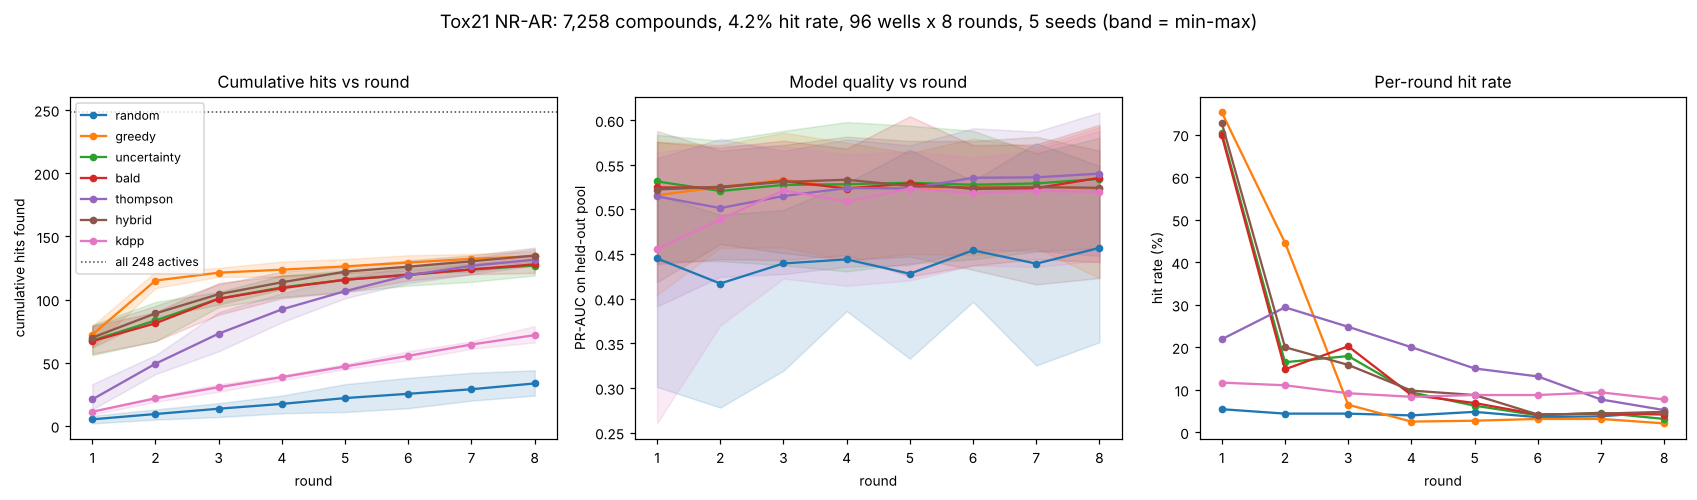

In [5]:
n_actives_tox21 = tox21_results["greedy"][0].n_actives
fig = plot_comparison(
    tox21_frame,
    n_actives=n_actives_tox21,
    title=("Tox21 NR-AR: 7,258 compounds, 4.2% hit rate, "
           "96 wells x 8 rounds, 5 seeds (band = min-max)"),
)
FIGDIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGDIR / "02_headline_tox21_cumulative_hits.png", dpi=150, bbox_inches="tight")

In [6]:
def final_table(frame):
    last = frame[frame["round"] == frame["round"].max()]
    return last.groupby("policy").agg(
        hits=("cumulative_hits", "mean"),
        hits_sd=("cumulative_hits", "std"),
        found=("fraction_of_achievable", "mean"),
        pr_auc=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),
    ).round(3).sort_values("hits", ascending=False)

final_table(tox21_frame)

,hits,hits_sd,found,pr_auc,pr_auc_sd
policy,,,,,
hybrid,134.8,4.970,0.549,0.524,0.060
greedy,134.2,3.564,0.546,0.523,0.063
thompson,131.6,5.128,0.535,0.540,0.061
bald,127.8,5.263,0.520,0.535,0.058
uncertainty,126.8,4.919,0.516,0.534,0.049
kdpp,71.8,4.658,0.292,0.520,0.058
random,33.6,8.735,0.136,0.457,0.071


### Read that table honestly

Greedy is at or near the top on hits, and the final PR-AUC column is flat
across every model-driven policy -- the differences are smaller than the
seed-to-seed standard deviation. **On this dataset, at this budget, the
information-seeking policies do not buy a better model, and they do not buy
more hits.**

The only policy clearly separated is `random`, which is worse at both. That is
worth stating plainly: the single largest effect here is "use the model at
all", and everything after that is a second-order choice.

So where does exploration earn anything? Look at the *marginal* productivity
rather than the cumulative total.

policy,bald,greedy,hybrid,kdpp,random,thompson,uncertainty
round,,,,,,,
1,69.8,75.2,72.7,11.7,5.4,21.9,70.4
2,14.8,44.6,20.0,11.0,4.4,29.4,16.5
3,20.2,6.5,15.8,9.2,4.4,24.8,17.9
4,8.8,2.5,9.8,8.3,4.0,20.0,9.4
5,6.9,2.7,8.8,8.8,4.8,15.0,6.2
6,4.2,3.1,4.2,8.8,3.5,13.1,4.0
7,4.4,3.1,4.4,9.4,3.8,7.7,4.6
8,4.2,2.1,4.8,7.7,4.8,5.2,3.1


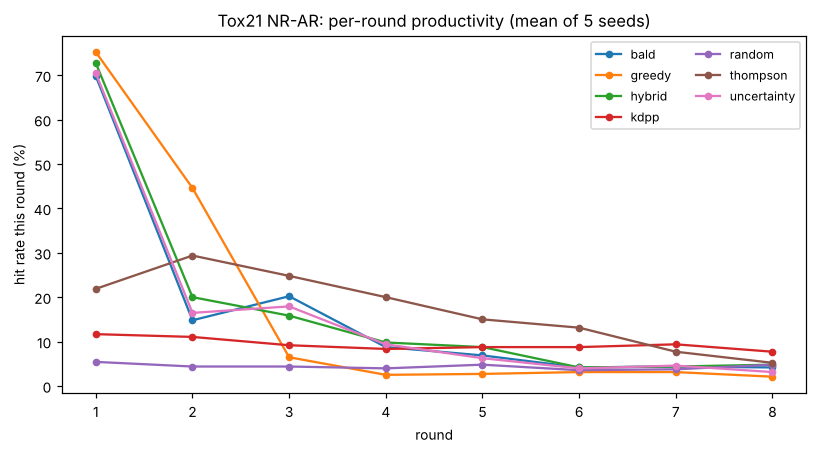

In [7]:
per_round = tox21_frame.pivot_table(index="round", columns="policy", values="hit_rate")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for policy in per_round.columns:
    ax.plot(per_round.index, per_round[policy] * 100, "o-", label=policy, ms=4)
ax.set_xlabel("round"); ax.set_ylabel("hit rate this round (%)")
ax.set_title("Tox21 NR-AR: per-round productivity (mean of 5 seeds)")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGDIR / "02_tox21_per_round_hit_rate.png", dpi=150, bbox_inches="tight")
(per_round * 100).round(1)

Greedy's hit rate rises, peaks, and falls. It is consuming a chemotype: the
model knows one region of chemical space, that region has a finite number of
members, and every well spent there confirms what the model already believed.
The diversity-constrained policy's rate is flat or rising over the same rounds.

With 8 rounds of 96 (768 of 7,258 compounds) greedy never runs out. Extend the
horizon and the picture changes -- that experiment is in the README.

## Dataset 2: BACE-1, a dose-response screen

1,513 inhibitors of human beta-secretase 1, each with a measured IC50
(Subramanian et al., 2016). BACE-1 is the enzyme that makes the first cut in
amyloid precursor protein, so it has been an Alzheimer's target for two
decades.

This dataset differs from Tox21 in three ways that matter:

1. **Potency is continuous.** `pIC50` is the negative log10 of the IC50
   concentration: 7.0 means 100 nM, and each unit is a tenfold improvement. We
   threshold at 7.0 to define a "hit", which gives a 44.6% hit rate -- and that
   number is a *choice*. Where you put the threshold decides your hit rate, so
   a campaign's apparent success is partly a decision about bookkeeping.
2. **It is pre-enriched.** These are published inhibitors of one target, not a
   diverse library, so the chemistry is narrow.
3. **It ships with 590 computed physicochemical descriptors**, so no chemistry
   toolkit is needed.

The budget here is 24 wells per round over 10 rounds -- a small-n campaign, the
case Loopwise is named for.

In [8]:
bace, bace_info = load_bace(potency_threshold=7.0, use_descriptors=True)
print({k: v for k, v in bace_info.items() if k != "feature_cols"})
bace[["compound_id", "pIC50", "label"]].describe().round(2)

{'featurizer': 'published_descriptors', 'n_features': 364, 'dataset': 'BACE-1', 'source_url': 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv', 'citation': 'Subramanian, Ramsundar, Pande & Denny, J. Chem. Inf. Model. 56(10):1936-1949 (2016); distributed via MoleculeNet (Wu et al., Chem. Sci. 2018).', 'n_compounds': 1513, 'n_actives': 674, 'hit_rate': 0.4455, 'potency_threshold_pIC50': 7.0, 'task': 'regression or classification'}


,pIC50,label
count,1513.00,1513.00
mean,6.52,0.45
std,1.34,0.50
min,2.54,0.00
25%,5.59,0.00
50%,6.76,0.00
75%,7.54,1.00
max,10.52,1.00


In [9]:
bace_frame, bace_results = compare_policies(
    bace,
    label_col="label",
    model_factory=forest,
    policies=POLICIES,
    seeds=SEEDS,
    feature_cols=bace_info["feature_cols"],
    id_col="compound_id",
    budget=24,
    n_rounds=10,
    n_initial_labels=24,
    holdout_fraction=0.2,
    verbose=True,
)
bace_frame.to_csv(TABDIR / "02_bace_rounds.csv", index=False)
final_table(bace_frame)

[replay] policy=random seed=0


   random: 108/541 actives (20.0%) after 10 rounds of 24; final PR-AUC 0.955; rounds to 50% of actives: not reached; 5.3s
[replay] policy=random seed=1


   random: 101/543 actives (18.6%) after 10 rounds of 24; final PR-AUC 0.878; rounds to 50% of actives: not reached; 5.0s
[replay] policy=random seed=2


   random: 108/539 actives (20.0%) after 10 rounds of 24; final PR-AUC 0.927; rounds to 50% of actives: not reached; 5.5s
[replay] policy=random seed=3


   random: 107/541 actives (19.8%) after 10 rounds of 24; final PR-AUC 0.953; rounds to 50% of actives: not reached; 5.4s
[replay] policy=random seed=4


...

   kdpp: 203/543 actives (37.4%) after 10 rounds of 24; final PR-AUC 0.856; rounds to 50% of actives: not reached; 5.6s
[replay] policy=kdpp seed=2


   kdpp: 198/539 actives (36.7%) after 10 rounds of 24; final PR-AUC 0.899; rounds to 50% of actives: not reached; 5.0s
[replay] policy=kdpp seed=3


   kdpp: 198/541 actives (36.6%) after 10 rounds of 24; final PR-AUC 0.909; rounds to 50% of actives: not reached; 5.3s
[replay] policy=kdpp seed=4


   kdpp: 197/541 actives (36.4%) after 10 rounds of 24; final PR-AUC 0.940; rounds to 50% of actives: not reached; 5.3s


,hits,hits_sd,found,pr_auc,pr_auc_sd
policy,,,,,
greedy,224.6,7.369,0.415,0.864,0.033
kdpp,199.4,2.510,0.369,0.910,0.035
hybrid,180.4,9.450,0.333,0.900,0.036
thompson,153.6,2.510,0.284,0.941,0.028
bald,123.0,4.183,0.227,0.946,0.013
uncertainty,122.4,5.550,0.226,0.931,0.019
random,105.0,3.674,0.194,0.932,0.032


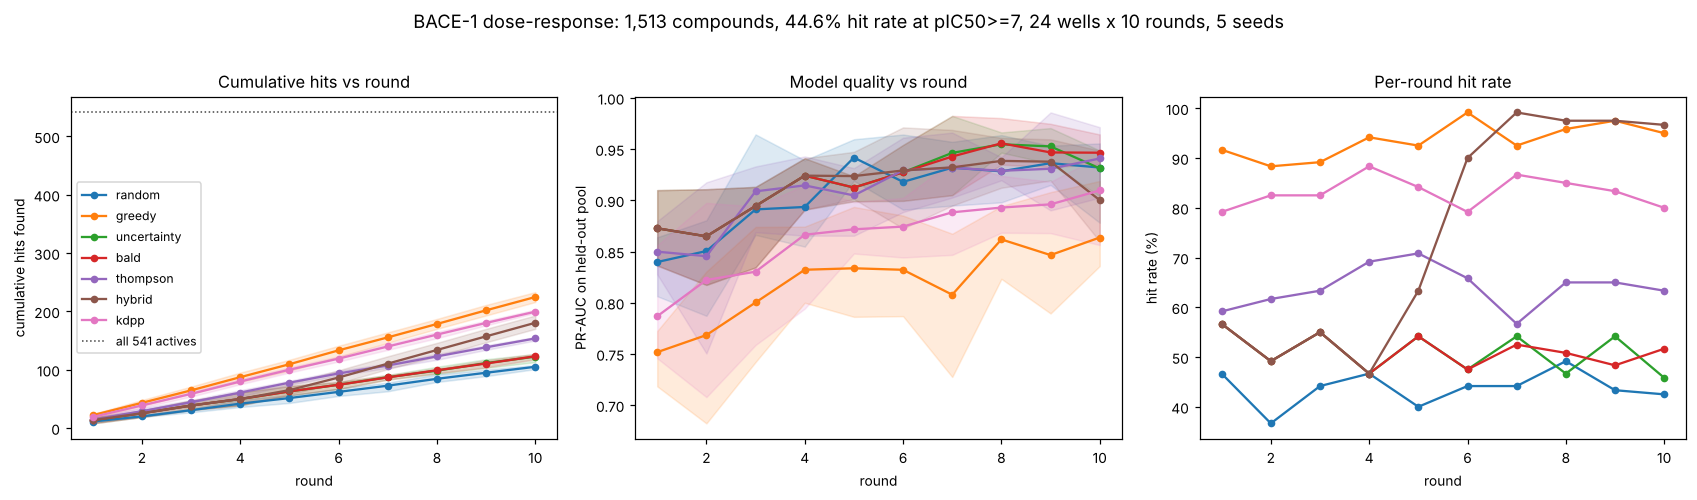

In [10]:
fig = plot_comparison(
    bace_frame,
    n_actives=bace_results["greedy"][0].n_actives,
    title=("BACE-1 dose-response: 1,513 compounds, 44.6% hit rate at pIC50>=7, "
           "24 wells x 10 rounds, 5 seeds"),
)
fig.savefig(FIGDIR / "02_bace_cumulative_hits.png", dpi=150, bbox_inches="tight")

### The trade-off, finally visible

On BACE the two objectives come apart cleanly. Greedy finds far more hits than
BALD *and* ends with the worst model of any policy -- worse than `random`.

That is the trade-off this package is about, measured rather than asserted. It
also makes the choice concrete: if the campaign's deliverable is a shortlist of
actives, greedy. If the deliverable is a model you will use on the next target,
greedy is destroying the thing you are paying for.

,hits,pr_auc
policy,,
greedy,224.6,0.864
kdpp,199.4,0.910
hybrid,180.4,0.900
thompson,153.6,0.941
bald,123.0,0.946
uncertainty,122.4,0.931
random,105.0,0.932


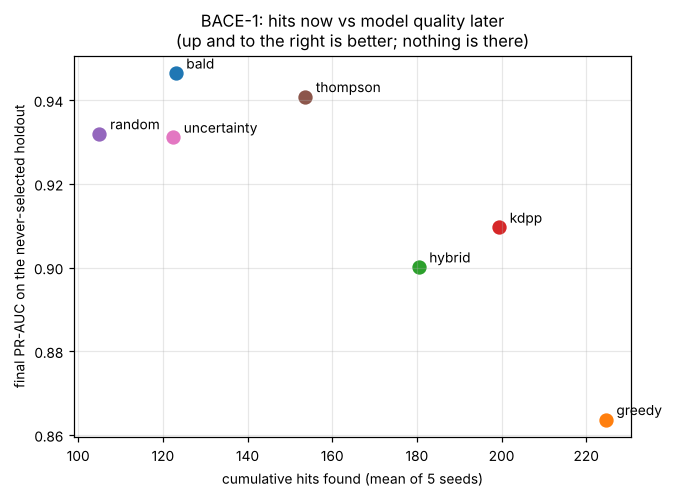

In [11]:
last = bace_frame[bace_frame["round"] == bace_frame["round"].max()]
agg = last.groupby("policy").agg(hits=("cumulative_hits", "mean"),
                                 pr_auc=("pr_auc", "mean"))
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for policy, row in agg.iterrows():
    ax.scatter(row["hits"], row["pr_auc"], s=70)
    ax.annotate(policy, (row["hits"], row["pr_auc"]),
                textcoords="offset points", xytext=(7, 3), fontsize=9)
ax.set_xlabel("cumulative hits found (mean of 5 seeds)")
ax.set_ylabel("final PR-AUC on the never-selected holdout")
ax.set_title("BACE-1: hits now vs model quality later\n(up and to the right is better; nothing is there)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGDIR / "02_bace_hits_vs_model_quality.png", dpi=150, bbox_inches="tight")
agg.round(3).sort_values("hits", ascending=False)

## Rounds to reach half the achievable hits

The operational question is rarely "how many actives in total" -- it is "how
many plates until I have enough to move on". `rounds_to_fraction` answers it.

In [12]:
rows = []
for name, dataset in (("Tox21 NR-AR", tox21_results), ("BACE-1", bace_results)):
    for policy, runs in dataset.items():
        reached = [r.rounds_to_fraction(0.5) for r in runs]
        got = [r for r in reached if r is not None]
        rows.append({
            "dataset": name,
            "policy": policy,
            "rounds_to_50pct": np.mean(got).round(1) if got else None,
            "seeds_reaching_50pct": f"{len(got)}/{len(runs)}",
            "final_pr_auc": round(float(np.mean([r.final_pr_auc for r in runs])), 3),
        })
pd.DataFrame(rows).pivot(index="policy", columns="dataset",
                         values=["rounds_to_50pct", "final_pr_auc"])

rounds_to_50pct             final_pr_auc            
dataset              BACE-1 Tox21 NR-AR       BACE-1 Tox21 NR-AR
policy                                                          
bald                    NaN         6.8        0.946       0.535
greedy                  NaN         4.0        0.864       0.523
hybrid                  NaN         5.8        0.900       0.524
kdpp                    NaN         NaN        0.910       0.520
random                  NaN         NaN        0.932       0.457
thompson                NaN         7.0        0.941       0.540
uncertainty             NaN         7.0        0.931       0.534

## Does a noisy assay change the answer?

Everything above assumes the measurement is correct. Real assays are not. With
`label_noise=0.2`, each revealed label has a 20% chance of being flipped when
the model sees it -- while scoring still uses the true labels, so we measure how
much of a policy's advantage survives.

In [13]:
noisy_frame, noisy_results = compare_policies(
    tox21,
    label_col="label",
    model_factory=forest,
    policies=["random", "greedy", "bald", "hybrid"],
    seeds=(0, 1, 2),
    feature_cols=tox21_info["feature_cols"],
    id_col="mol_id",
    budget=96,
    n_rounds=6,
    n_initial_labels=96,
    label_noise=0.2,
    verbose=False,
)
clean_frame, _ = compare_policies(
    tox21,
    label_col="label",
    model_factory=forest,
    policies=["random", "greedy", "bald", "hybrid"],
    seeds=(0, 1, 2),
    feature_cols=tox21_info["feature_cols"],
    id_col="mol_id",
    budget=96,
    n_rounds=6,
    n_initial_labels=96,
    verbose=False,
)
comparison = pd.DataFrame({
    "clean": final_table(clean_frame)["hits"],
    "20% label noise": final_table(noisy_frame)["hits"],
})
comparison["lost to noise"] = (comparison["clean"] - comparison["20% label noise"]).round(1)
comparison.round(1)

,clean,20% label noise,lost to noise
policy,,,
greedy,131.0,124.7,6.3
hybrid,129.3,97.0,32.3
bald,119.7,72.3,47.3
random,30.3,30.3,0.0


## What replay cannot tell you

Worth being explicit, because this notebook is the repo's main claim:

1. **The pool is a measured library, not yours.** Tox21 compounds were selected
   for a screening programme; a vendor catalogue is less information-rich and
   its hit rate is lower.
2. **No synthesis delay, no attrition, no compound availability.** Round 4 here
   happens instantly; in a lab it happens in six weeks.
3. **The featurization is frozen.** Real campaigns change their features as
   they learn the chemistry, and that often matters more than the selection
   policy does.
4. **One dataset is one dataset.** We ran two, they disagreed, and the honest
   conclusion is the conditional one: *which* policy wins depends on the hit
   rate, the budget-to-pool ratio, the horizon, and which deliverable you are
   paying for.

Run `loopwise replay tox21 --n-seeds 5` to reproduce the Tox21 panel from the
command line.